In [86]:
import sys
sys.path.append("../")
from collections import defaultdict

import pyarrow.feather as feather
import numpy as np
import itertools
from pathlib import Path
from utils import *
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
import networkx as nx

from tqdm.auto import tqdm

import seaborn as sns
sns.set_context("notebook", font_scale=1.2)
colors = sns.color_palette("muted")

from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import r2_score

import matplotlib.pyplot as plt
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update(plt.rcParamsDefault)
plt.rcParams.update({"font.size" : 15,
                     "figure.dpi" : 100, 
                     "grid.alpha" : 0.3, 
                     "axes.grid": False, 
                     "axes.axisbelow" : True,
                     "figure.figsize":(8,6),
                     "mathtext.fontset":"cm",
                     "xtick.labelsize": 14,
                     "ytick.labelsize": 14,
                     "axes.labelsize": 16, 
                     "legend.fontsize": 13.5})
plt.rc("text", usetex=False)
plt.rc("font", family="serif")

In [87]:
DATA_DIR = Path("../data/burnin_diagnostic/")

snap_df = feather.read_feather(DATA_DIR / "burnin_snapshots.arrow")
casc_df = feather.read_feather(DATA_DIR / "burnin_cascades.arrow")

cfg = {}
with open(DATA_DIR / "diagnostic_config.txt") as f:
    for line in f:
        k, v = line.strip().split(" = ")
        try:    cfg[k] = float(v)
        except: cfg[k] = v

BURN_IN   = int(cfg["burn_in_length"])
TRUE_PREV = 1.0 - cfg["p_fake"]
TRUE_TPR  = cfg["tpr"]
TRUE_FPR  = cfg["fpr"]

PARAM_STR = (f"v_cost={cfg['v_cost']}  loss={cfg['rep_loss']}  "
             f"tpr={cfg['tpr']}  fpr={cfg['fpr']}  p_fake={cfg['p_fake']}")

print(f"Reps        : {snap_df['rep_id'].nunique()}")
print(f"Timepoints  : {snap_df['cascade_id'].nunique()}")
print(f"Burn-in     : {BURN_IN} cascades")
print(f"Parameters: " + PARAM_STR)

Reps        : 50
Timepoints  : 2200
Burn-in     : 2000 cascades
Parameters: v_cost=0.01  loss=3.0  tpr=0.85  fpr=0.1  p_fake=0.2


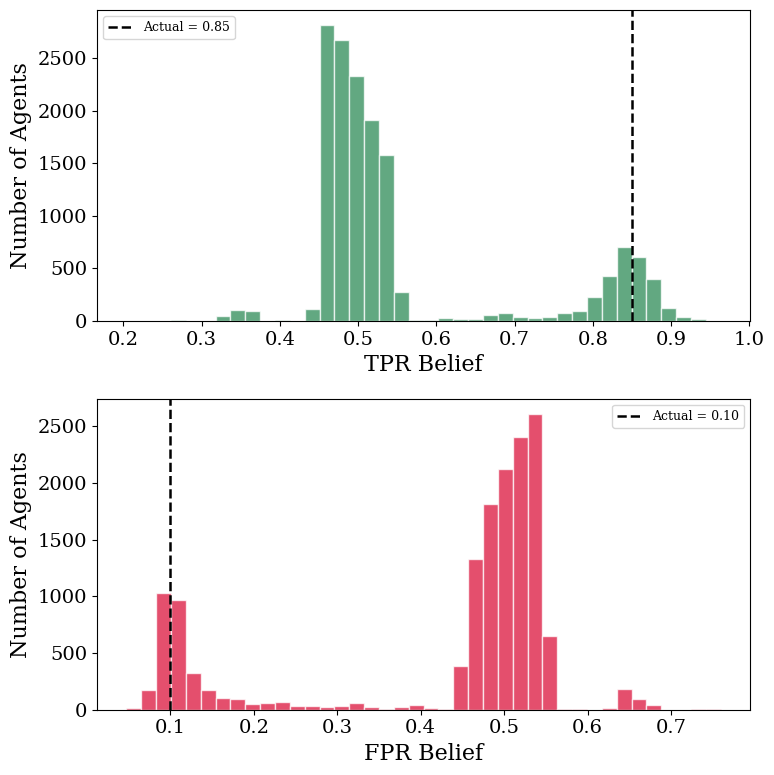

In [88]:
all_cids        = sorted(snap_df["cascade_id"].unique())
t_burnin_actual = min(all_cids, key=lambda x: abs(x - BURN_IN))
timepoints      = [t_burnin_actual]

dist_panels = [
    ("tpr_mean",  "Number of Agents", TRUE_TPR,  "seagreen", "TPR Belief"),
    ("fpr_mean",  "Number of Agents", TRUE_FPR,  "crimson", "FPR Belief"),
]

fig, axes = plt.subplots(2, 1, figsize=(8, 8), sharey="row")

for row, (col, ylabel, truth, color, xlabel) in enumerate(dist_panels):
    for col_i, t in enumerate(timepoints):
        ax = axes[row]
        data = snap_df[snap_df["cascade_id"] == t][col].dropna()
        ax.hist(data, bins=40, color=color, alpha=0.75, edgecolor="white")
        if truth is not None:
            ax.axvline(truth, color="black", lw=1.8, ls="--", label=f"Actual = {truth:.2f}")
            ax.legend(fontsize=9)
        if col_i == 0:
            ax.set_ylabel(ylabel)
        ax.set_xlabel(xlabel)

fig.tight_layout()
plt.show()

In [89]:
start = snap_df[snap_df["cascade_id"]==1]
end = snap_df[snap_df["cascade_id"]==2000]

In [5]:
not_verifying = end[end["verify_count"]==0]
verifying = end[end["verify_count"]!=0]

idx_not_verifying = not_verifying[["rep_id", "node_id"]]
idx_verifying = verifying[["rep_id", "node_id"]]

start_not_verifying = start.merge(idx_not_verifying, on=["rep_id", "node_id"])
start_verifying = start.merge(idx_verifying, on=["rep_id", "node_id"])

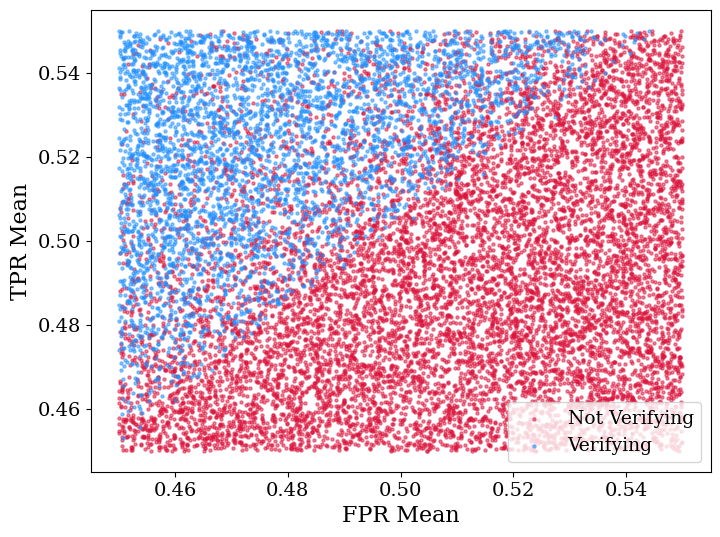

In [6]:
plt.scatter(start_not_verifying["fpr_mean"], start_not_verifying["tpr_mean"], color="crimson", alpha=0.5, label="Not Verifying", s=5)
plt.scatter(start_verifying["fpr_mean"], start_verifying["tpr_mean"], color="dodgerblue", alpha=0.5, label="Verifying", s=5)

plt.xlabel("FPR Mean")
plt.ylabel("TPR Mean")
plt.legend()
plt.show()

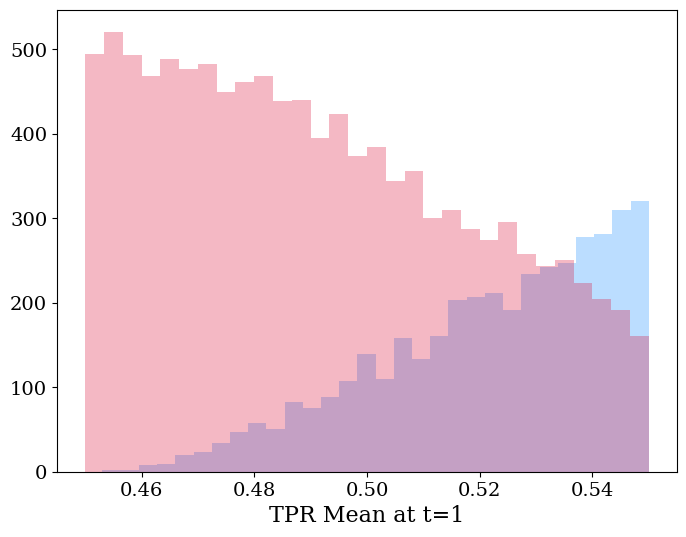

In [7]:
plt.hist(start_verifying["tpr_mean"], color="dodgerblue", alpha=0.3, bins=30)
plt.hist(start_not_verifying["tpr_mean"], color="crimson", alpha=0.3, bins=30)
plt.xlabel("TPR Mean at t=1")
plt.show()

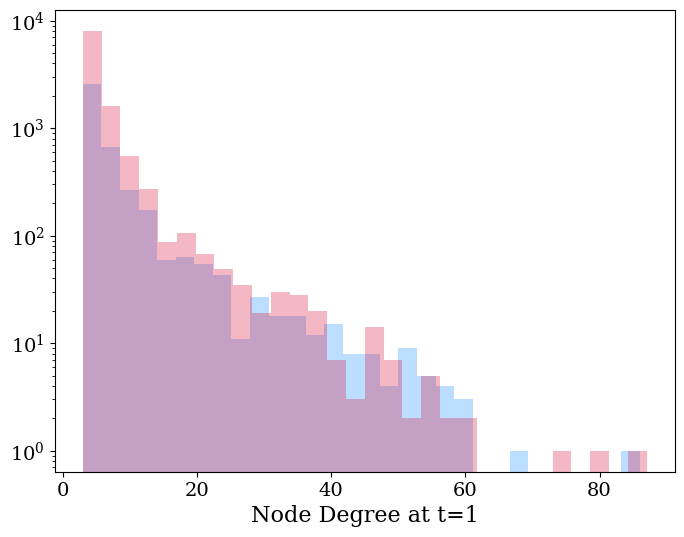

In [11]:
plt.hist(start_verifying["node_degree"], color="dodgerblue", alpha=0.3, bins=30)
plt.hist(start_not_verifying["node_degree"], color="crimson", alpha=0.3, bins=30)
plt.xlabel("Node Degree at t=1")
plt.yscale("log")
plt.show()

In [ ]:
start_verifying

,rep_id,cascade_id,phase,node_id,true_mean,tpr_mean,fpr_mean,true_n,tpr_n,fpr_n,mean_trust,mean_trust_n,node_degree,betweenness,closeness,eigenvector,verify_count
0,1,1,burnin,2,0.501521,0.534097,0.450599,2.0,2.0,2.0,0.510908,2.139651,37,0.113859,0.458589,0.292342,0
1,1,1,burnin,9,0.523855,0.541458,0.512594,2.0,2.0,2.0,0.539624,1.974779,27,0.063690,0.416435,0.164000,0
2,1,1,burnin,10,0.506854,0.466685,0.459304,2.0,2.0,2.0,0.488341,2.008815,14,0.018894,0.386305,0.125905,0
3,1,1,burnin,13,0.463653,0.528691,0.482905,2.0,2.0,2.0,0.498874,2.019918,20,0.032577,0.378961,0.111949,0
4,1,1,burnin,14,0.492461,0.545927,0.494029,2.0,2.0,2.0,0.494552,2.027194,21,0.058954,0.414127,0.134211,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4031,50,1,burnin,287,0.450451,0.479135,0.454922,2.0,2.0,2.0,0.466123,1.951672,3,0.001385,0.371429,0.049151,0
4032,50,1,burnin,292,0.461640,0.539069,0.530856,2.0,2.0,2.0,0.489520,2.116865,3,0.000000,0.370968,0.059775,0
4033,50,1,burnin,295,0.473988,0.540279,0.463348,2.0,2.0,2.0,0.511036,2.004766,3,0.000829,0.304481,0.015686,0
4034,50,1,burnin,296,0.522369,0.519188,0.464648,2.0,2.0,2.0,0.496493,1.996952,3,0.000706,0.269127,0.005969,0


### Logistic Regression

In [66]:
feature_vecs_verifying = np.array(start_verifying[["tpr_mean", "fpr_mean", "true_mean", "node_degree"]])
y_verifying = np.ones((len(feature_vecs_verifying,)))

feature_vecs_non_verifying = np.array(start_not_verifying[["tpr_mean", "fpr_mean", "true_mean", "node_degree"]])
y_non_verifying = np.zeros((len(feature_vecs_non_verifying,)))

X = np.vstack([feature_vecs_verifying, feature_vecs_non_verifying])
y = np.concatenate([y_verifying, y_non_verifying])

In [67]:
m = LogisticRegression().fit(X, y)

m.score(X, y)

0.835

In [68]:
end

,rep_id,cascade_id,phase,node_id,true_mean,tpr_mean,fpr_mean,true_n,tpr_n,fpr_n,mean_trust,mean_trust_n,node_degree,betweenness,closeness,eigenvector,verify_count
599700,1,2000,burnin,1,0.824106,0.470648,0.493284,1541.0,2.0,2.0,0.742080,60.969534,26,0.062780,0.432081,0.198971,0
599701,1,2000,burnin,2,0.824221,0.534097,0.633733,1536.0,2.0,3.0,0.765089,43.518030,37,0.113859,0.458589,0.292342,1
599702,1,2000,burnin,3,0.824550,0.528020,0.528045,1539.0,2.0,2.0,0.797123,60.766675,26,0.077738,0.427754,0.186547,0
599703,1,2000,burnin,4,0.824771,0.467718,0.472042,1541.0,2.0,2.0,0.781303,30.332953,54,0.235035,0.496678,0.385482,0
599704,1,2000,burnin,5,0.824412,0.491902,0.493592,1538.0,2.0,2.0,0.739299,44.599392,36,0.116778,0.452345,0.248754,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32939995,50,2000,burnin,296,0.820049,0.346126,0.137807,1728.0,3.0,14.0,0.844195,575.996952,3,0.000706,0.269127,0.005969,13
32939996,50,2000,burnin,297,0.820297,0.547047,0.517126,1731.0,2.0,2.0,0.799220,576.701852,3,0.000485,0.361548,0.057209,0
32939997,50,2000,burnin,298,0.819609,0.907406,0.106196,1730.0,215.0,178.0,0.586898,576.094114,3,0.000433,0.312435,0.017240,389
32939998,50,2000,burnin,299,0.820192,0.512709,0.537078,1730.0,2.0,2.0,0.770216,575.914707,3,0.000017,0.353011,0.050478,0


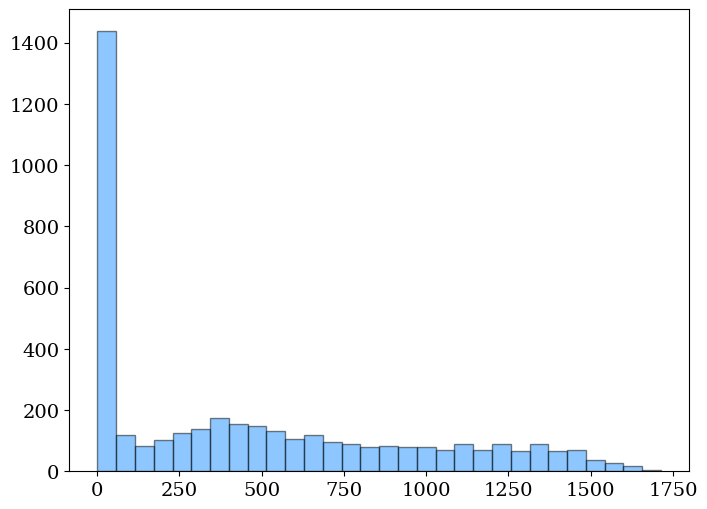

In [82]:
plt.hist(
    end[end["verify_count"]>0]["verify_count"],
    bins=30,
    color="dodgerblue",
    alpha=0.5,
    edgecolor="k"
)
plt.show()

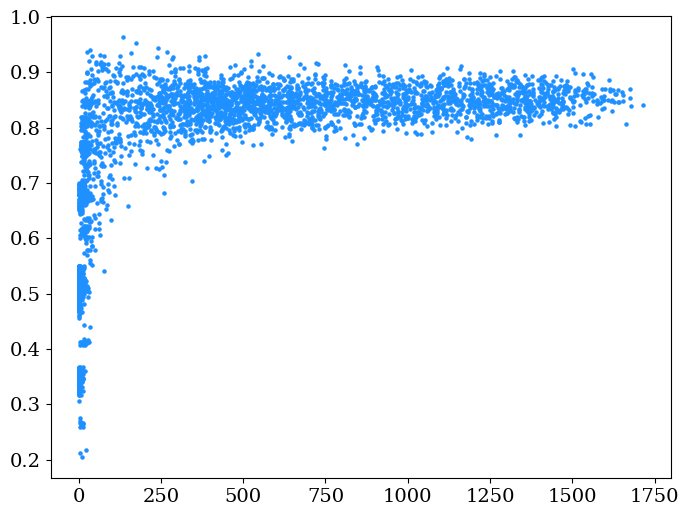

In [80]:
plt.scatter(
    end[end["verify_count"]>0]["verify_count"],
    end[end["verify_count"]>0]["tpr_mean"],
    color="dodgerblue", 
    s=5
)
plt.show()

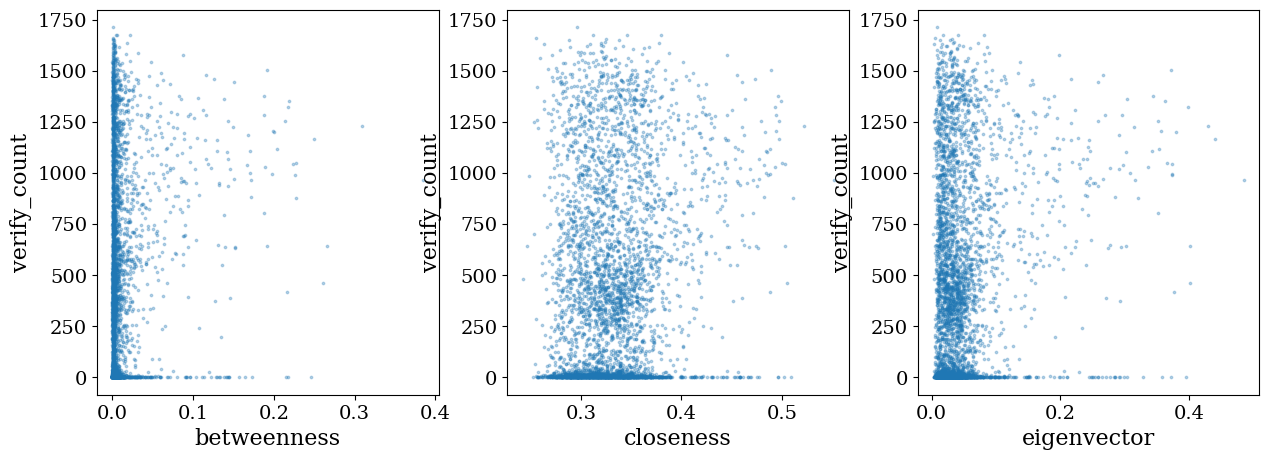

In [85]:
verifiers = end[end["verify_count"] > 0]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, col in zip(axes, ["betweenness", "closeness", "eigenvector"]):
    ax.scatter(verifiers[col], verifiers["verify_count"], s=3, alpha=0.3)
    ax.set_xlabel(col)
    ax.set_ylabel("verify_count")

plt.show()

In [90]:
# per-exposure verification probability
end["verify_rate"] = end["verify_count"] / end["exposure_count"]

# basic sanity check
print(end[["verify_count", "exposure_count", "verify_rate"]].describe())

       verify_count  exposure_count   verify_rate
count  15000.000000    15000.000000  15000.000000
mean     125.061533     1620.916467      0.078362
std      322.879803      137.915229      0.201780
min        0.000000      884.000000      0.000000
25%        0.000000     1579.000000      0.000000
50%        0.000000     1650.000000      0.000000
75%        1.000000     1691.000000      0.000625
max     1714.000000     1850.000000      0.996863


/var/folders/mz/n_rzzjx149d19ncnxglpf7n40000gn/T/ipykernel_46586/173165696.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  end["verify_rate"] = end["verify_count"] / end["exposure_count"]


In [95]:
from scipy.stats import spearmanr
import seaborn as sns

static_vars = ["tpr_mean", "fpr_mean", "true_mean", 
               "node_degree", "betweenness", "closeness", "eigenvector"]

# get t=1 values merged onto end-state data
start = snap_df[snap_df["cascade_id"] == 1].copy()
start = start.rename(columns={c: f"{c}_t1" for c in static_vars})

merged = end.merge(
    start[["rep_id", "node_id"] + [f"{c}_t1" for c in static_vars]],
    on=["rep_id", "node_id"]
)

# Spearman correlations (rank-based, robust to the skewed distributions)
print(f"\n{'Variable':<25} {'r with verify_count':>20} {'r with verify_rate':>20}")
for v in static_vars:
    r_count, _ = spearmanr(merged[f"{v}_t1"], merged["verify_count"])
    r_rate,  _ = spearmanr(merged[f"{v}_t1"], merged["verify_rate"])
    print(f"{v:<25} {r_count:>20.4f} {r_rate:>20.4f}")


Variable                   r with verify_count   r with verify_rate
tpr_mean                                0.4570               0.4569
fpr_mean                               -0.4518              -0.4518
true_mean                               0.0108               0.0109
node_degree                             0.1158               0.1154
betweenness                             0.1072               0.1068
closeness                               0.0838               0.0833
eigenvector                             0.0836               0.0833


In [92]:
print(f"\n{'Variable':<25} {'r with exposure_count':>22}")
for v in static_vars:
    r, p = spearmanr(merged[f"{v}_t1"], merged["exposure_count"])
    print(f"{v:<25} {r:>22.4f}  (p={p:.3e})")


Variable                   r with exposure_count
tpr_mean                                  0.0112  (p=1.710e-01)
fpr_mean                                 -0.0038  (p=6.452e-01)
true_mean                                -0.0008  (p=9.244e-01)
node_degree                               0.0192  (p=1.840e-02)
betweenness                               0.0248  (p=2.354e-03)
closeness                                 0.0211  (p=9.728e-03)
eigenvector                               0.0139  (p=8.879e-02)


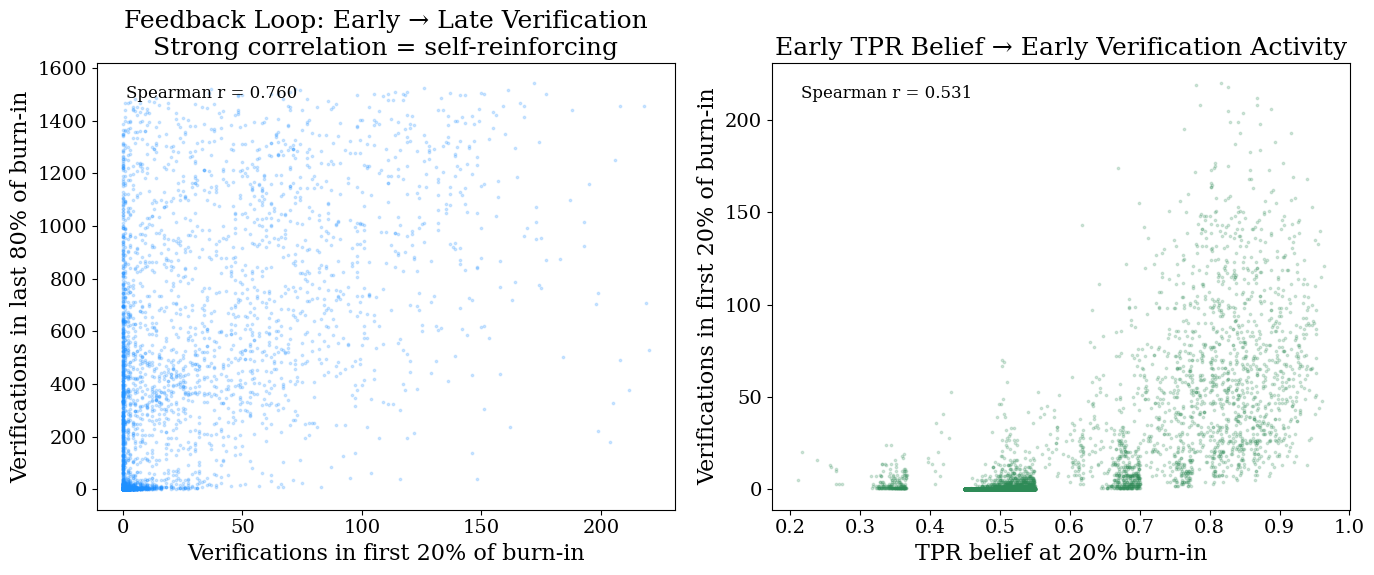

In [99]:
# compute verify_count increments between early and late windows
early_end = snap_df[snap_df["cascade_id"] == int(BURN_IN * 0.2)][
    ["rep_id", "node_id", "verify_count", "tpr_mean", "fpr_mean"]
].rename(columns={
    "verify_count": "vc_early",
    "tpr_mean": "tpr_early",
    "fpr_mean": "fpr_early"
})

late_end = snap_df[snap_df["cascade_id"] == BURN_IN][
    ["rep_id", "node_id", "verify_count", "tpr_mean", "fpr_mean"]
].rename(columns={
    "verify_count": "vc_late",
    "tpr_mean": "tpr_late",
    "fpr_mean": "fpr_late"
})

rates = early_end.merge(late_end, on=["rep_id", "node_id"])

# verifications accumulated in each window
# early window: cascade 1 → 20% burn-in
# late window:  80% → 100% burn-in
# since snapshot cadence=1, these are just the counts at those timepoints
rates["vc_delta_early"] = rates["vc_early"]  # verifications in first 20%
rates["vc_delta_late"]  = rates["vc_late"] - rates["vc_early"]  # verifications in last 80%

# feedback loop plot
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# left: early vs late verify count — are early verifiers also late verifiers?
ax = axes[0]
ax.scatter(rates["vc_delta_early"], rates["vc_delta_late"], 
           s=3, alpha=0.2, color="dodgerblue")
ax.set_xlabel("Verifications in first 20% of burn-in")
ax.set_ylabel("Verifications in last 80% of burn-in")
ax.set_title("Feedback Loop: Early → Late Verification\n"
             "Strong correlation = self-reinforcing")

# add correlation
r, p = spearmanr(rates["vc_delta_early"], rates["vc_delta_late"])
ax.text(0.05, 0.95, f"Spearman r = {r:.3f}", transform=ax.transAxes,
        va="top", fontsize=12)

# right: does early tpr belief predict early verification rate?
ax = axes[1]
ax.scatter(rates["tpr_early"], rates["vc_delta_early"],
           s=3, alpha=0.2, color="seagreen")
ax.set_xlabel("TPR belief at 20% burn-in")
ax.set_ylabel("Verifications in first 20% of burn-in")
ax.set_title("Early TPR Belief → Early Verification Activity")

r2, p2 = spearmanr(rates["tpr_early"], rates["vc_delta_early"])
ax.text(0.05, 0.95, f"Spearman r = {r2:.3f}", transform=ax.transAxes,
        va="top", fontsize=12)

plt.tight_layout()
plt.show()

In [101]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from scipy.stats import spearmanr

scaler = StandardScaler()

# merge start beliefs onto rates df
start = snap_df[snap_df["cascade_id"] == 1][
    ["rep_id", "node_id", "tpr_mean", "fpr_mean", "true_mean",
     "node_degree", "betweenness", "closeness", "eigenvector"]
].rename(columns={c: f"{c}_t1" for c in 
                  ["tpr_mean", "fpr_mean", "true_mean", "node_degree",
                   "betweenness", "closeness", "eigenvector"]})

path_df = rates.merge(start, on=["rep_id", "node_id"])

# Step 1: initial beliefs → early verification activity
X1 = scaler.fit_transform(path_df[["tpr_mean_t1", "fpr_mean_t1"]])
y1 = path_df["vc_delta_early"].values
m1 = LinearRegression().fit(X1, y1)
print(f"Step 1 R² (initial beliefs → early verify count):  {m1.score(X1, y1):.3f}")

# Step 2: early verification → late verification (feedback loop)
X2 = path_df[["vc_delta_early"]].values
y2 = path_df["vc_delta_late"].values
m2 = LinearRegression().fit(X2, y2)
print(f"Step 2 R² (early verify count → late verify count): {m2.score(X2, y2):.3f}")

# Step 3: total verify count → final tpr accuracy
X3 = path_df[["vc_late"]].values
y3 = path_df["tpr_late"].values
m3 = LinearRegression().fit(X3, y3)
print(f"Step 3 R² (total verify count → final tpr_mean):    {m3.score(X3, y3):.3f}")

# baseline: direct path (what you originally measured)
X0 = scaler.fit_transform(path_df[["tpr_mean_t1", "fpr_mean_t1"]])
y0 = path_df["tpr_late"].values
m0 = LinearRegression().fit(X0, y0)
print(f"\nBaseline R² (initial beliefs → final tpr, direct):  {m0.score(X0, y0):.3f}")

Step 1 R² (initial beliefs → early verify count):  0.122
Step 2 R² (early verify count → late verify count): 0.458
Step 3 R² (total verify count → final tpr_mean):    0.625

Baseline R² (initial beliefs → final tpr, direct):  0.353
